# MC2: Augmentation: Swiss QR-Bill Image Quality

**Student:** Haris Salii  
**Country:** Switzerland  
**Semester:** HS26  
**Selected task:** Augmentation (Days 1–5)

## Day 1: Data & Domain

### Anwendungsfall

Für diese Aufgabe betrachte ich den QR-Zahlteil einer Schweizer Rechnung. Die Idee ist, dass eine Person den Zahlteil mit dem Smartphone fotografiert. Danach soll der QR-Code gefunden und für das spätere Auslesen vorbereitet werden. Im Code stehen unter anderem Konto, Referenz, Betrag, Währung und Adressen. Deshalb muss seine Struktur auf dem Bild möglichst gut erhalten bleiben.

### Problemstellung

Bei einem Smartphone-Foto können leichte Unschärfe oder Bildrauschen entstehen. Im QR-Code können dadurch Kanten weicher werden, schwarze Felder zusammenlaufen oder einzelne dunkle Pixel auftauchen. Entscheidend ist das schwarz-weisse Raster mit den drei grossen Suchmustern in den Ecken. Wenn sich dieses Raster zu stark verändert, kann das spätere Erkennen oder Auslesen schwieriger werden.

### Ziel des Versuchs

Ziel ist es zu untersuchen, wie typische Qualitätsverluste bei Smartphone-Aufnahmen die schwarz-weisse Modulstruktur des QR-Codes verändern. Dabei soll verglichen werden, wie stark die relevanten Strukturen beeinflusst werden und welche Bereiche besonders empfindlich reagieren. Die konkreten Augmentierungen und Parameter werden erst am zweiten Tag festgelegt.

### Datenquelle und Bildausschnitt

Als Beispiel verwende ich die Datei **„Nr. 1 englisch.jpg“** aus dem offiziellen SIX-Paket *Samples of the QR-bill – payment part*. Das Bild ist ein RGB-JPEG mit 1242 × 621 Pixeln. Es zeigt links den Empfangsschein und rechts den Zahlteil mit QR-Code und Zahlungsangaben. Für den Versuch verwende ich einen festen Ausschnitt von 300 × 300 Pixeln rund um den QR-Code. Darin sind das Modulraster, die drei Suchmuster, das Schweizer Kreuz und der weisse Rand sichtbar.

Quelle: [SIX-Beispielpaket](https://www.six-group.com/dam/download/banking-services/standardization/qr-bill/samples-payment-part-en.zip)  

In [10]:
import base64
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

SAMPLE_JPEG_BASE64 = "..."
payment_part = Image.open(BytesIO(base64.b64decode(SAMPLE_JPEG_BASE64))).convert("RGB")
payment_array = np.asarray(payment_part)
qqr_ausschnitt_rgb = payment_array[90:390, 380:680]
qr_ausschnitt_grau = np.asarray(Image.fromarray(qr_roi_rgb).convert("L"))

print(f"Full image shape: {payment_array.shape}")
print(f"QR region shape: {qr_roi_gray.shape}")


Full image shape: (621, 1242, 3)
QR region shape: (300, 300)


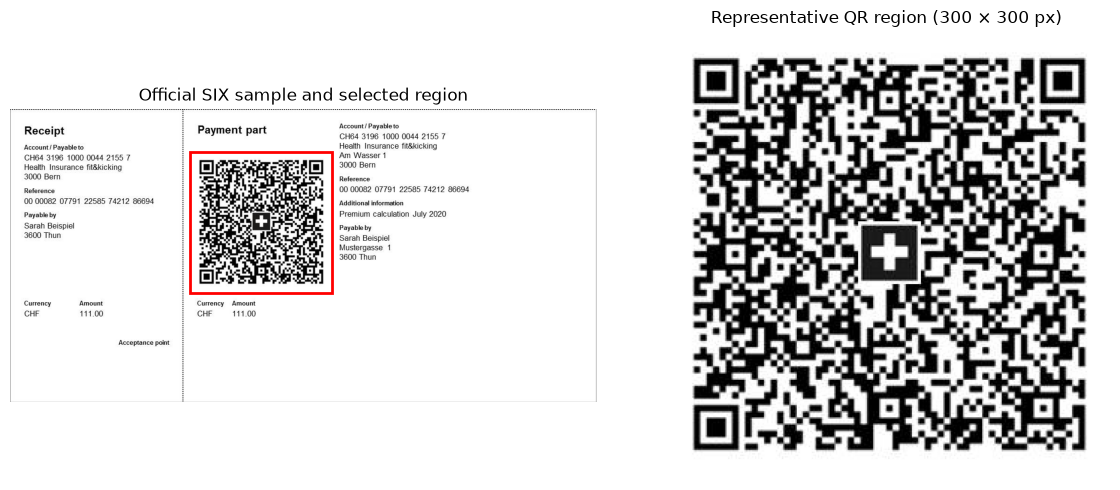

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(payment_array)
axes[0].add_patch(plt.Rectangle((380, 90), 300, 300, fill=False, edgecolor="red", linewidth=2))
axes[0].set_title("Official SIX sample and selected region")
axes[0].axis("off")
axes[1].imshow(qr_ausschnitt_grau, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Representative QR region (300 × 300 px)")
axes[1].axis("off")
fig.tight_layout()


**Beobachtung:** Im gewählten Ausschnitt dominieren klar abgegrenzte schwarze und weisse Quadrate. Die drei grossen Suchmuster sind gut sichtbar. Besonders empfindlich wirken die kleinen Felder und schmalen Zwischenräume, weil diese bei Unschärfe oder Rauschen schneller verändert werden können. Deshalb eignet sich dieser Ausschnitt gut für den geplanten Vergleich.


## Day 2: Methodological Design

### Auswahl der Augmentierungen

Ich verwende zwei nicht-geometrische Augmentierungen:

1. **Gaußsche Unschärfe:** Sie stellt eine leichte Fehlfokussierung der Kamera nach. Jeder Pixel wird dabei aus seinen Nachbarpixeln gemittelt. Dadurch werden die Kanten des QR-Rasters weicher und kleine Lücken können verschwinden.
2. **Gaußsches Rauschen:** Es stellt Schwankungen des Kamerasensors dar, zum Beispiel bei wenig Licht. Zu jedem Pixel wird ein zufälliger Wert addiert. Die Geometrie des QR-Codes bleibt dabei grundsätzlich gleich.

Für die Unschärfe gilt $I_b = G_{\sigma} * I$. Für das Rauschen verwende ich $I_n = \operatorname{clip}(I + \epsilon, 0, 255)$ mit $\epsilon \sim \mathcal{N}(0, \sigma_n^2)$.

### Gewählte Einstellungen

| Konfiguration | Veränderung | Parameter | Erwartete Wirkung |
|---|---|---|---|
| C0 | Referenz | keine | ursprüngliche Struktur |
| C1 | Gaußsche Unschärfe | Radius = 1,5 Pixel | weichere Kanten und teilweise zusammenlaufende Felder |
| C2 | Gaußsches Rauschen | Standardabweichung = 25; Seed = 42 | lokale helle und dunkle Störungen |

Die beiden Einstellungen sollen deutlich sichtbar sein, den QR-Code aber nicht vollständig zerstören. Mit dem festen Seed lässt sich das Rauschen bei jedem Durchlauf genau gleich erzeugen.

Die kleinsten Module des QR-Codes sind im Ausschnitt ungefähr 4–5 Pixel breit. Der Unschärferadius von 1,5 Pixeln entspricht damit etwa einem Drittel einer Modulbreite. Dadurch werden Kanten sichtbar weicher, ohne dass die QR-Struktur vollständig verschwindet. Die Standardabweichung von 25 entspricht ungefähr 10 % des möglichen Grauwertbereichs von 0 bis 255. Da der QR-Code einen sehr hohen Schwarz-Weiss-Kontrast besitzt, entstehen erkennbare Störungen, während die Grundstruktur grösstenteils erhalten bleibt. Der Seed 42 beeinflusst die Stärke nicht, sondern sorgt nur dafür, dass das Rauschen reproduzierbar ist.

### Versuchsaufbau und Grenzen

Für alle drei Konfigurationen verwende ich denselben Graustufen-Ausschnitt, dieselbe Bildgrösse, denselben Schwellenwert und dieselbe Auswertungsmetrik. Nur die Augmentierung ändert sich. Ich erwarte, dass C0 am besten abschneidet. C2 sollte mehr Struktur erhalten als C1, weil die Unschärfe direkt die Kanten verschiebt. Nicht abgedeckt sind unter anderem Perspektive, Schatten, Bewegungsunschärfe und JPEG-Kompression.


## Day 3: Technische Umsetzung

Zuerst teste ich beide Funktionen an einem einfachen, QR-ähnlichen Testbild. Danach wende ich die drei festgelegten Konfigurationen auf den SIX-Ausschnitt an. Der Ablauf ist immer gleich: **Ausgangsbild → QR-Ausschnitt → Augmentierung → Binärmaske**.

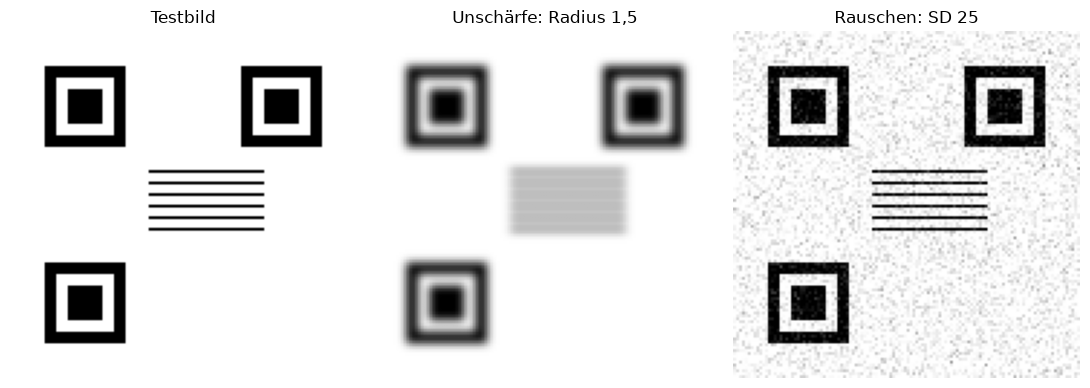

In [12]:
def gauss_unschaerfe(bild, radius):
    return np.asarray(Image.fromarray(bild).filter(ImageFilter.GaussianBlur(radius=radius)))


def gauss_rauschen(bild, standardabweichung, seed):
    generator = np.random.default_rng(seed)
    rauschen = generator.normal(0, standardabweichung, bild.shape)
    return np.clip(bild.astype(float) + rauschen, 0, 255).astype(np.uint8)


def schwarzmaske(bild, schwellenwert=128):
    return bild < schwellenwert


def suchmuster_einzeichnen(flaeche, oben, links, modul=4):
    flaeche[oben:oben + 7 * modul, links:links + 7 * modul] = 0
    flaeche[oben + modul:oben + 6 * modul, links + modul:links + 6 * modul] = 255
    flaeche[oben + 2 * modul:oben + 5 * modul, links + 2 * modul:links + 5 * modul] = 0


testbild = np.full((120, 120), 255, dtype=np.uint8)
suchmuster_einzeichnen(testbild, 12, 12)
suchmuster_einzeichnen(testbild, 12, 80)
suchmuster_einzeichnen(testbild, 80, 12)
testbild[48:72:4, 48:88] = 0
test_unscharf = gauss_unschaerfe(testbild, radius=1.5)
test_rauschen = gauss_rauschen(testbild, standardabweichung=25, seed=42)

abbildung, achsen = plt.subplots(1, 3, figsize=(11, 4))
for achse, bild, titel in zip(
    achsen,
    [testbild, test_unscharf, test_rauschen],
    ["Testbild", "Unschärfe: Radius 1,5", "Rauschen: SD 25"]
):
    achse.imshow(bild, cmap="gray", vmin=0, vmax=255)
    achse.set_title(titel)
    achse.axis("off")
abbildung.tight_layout()


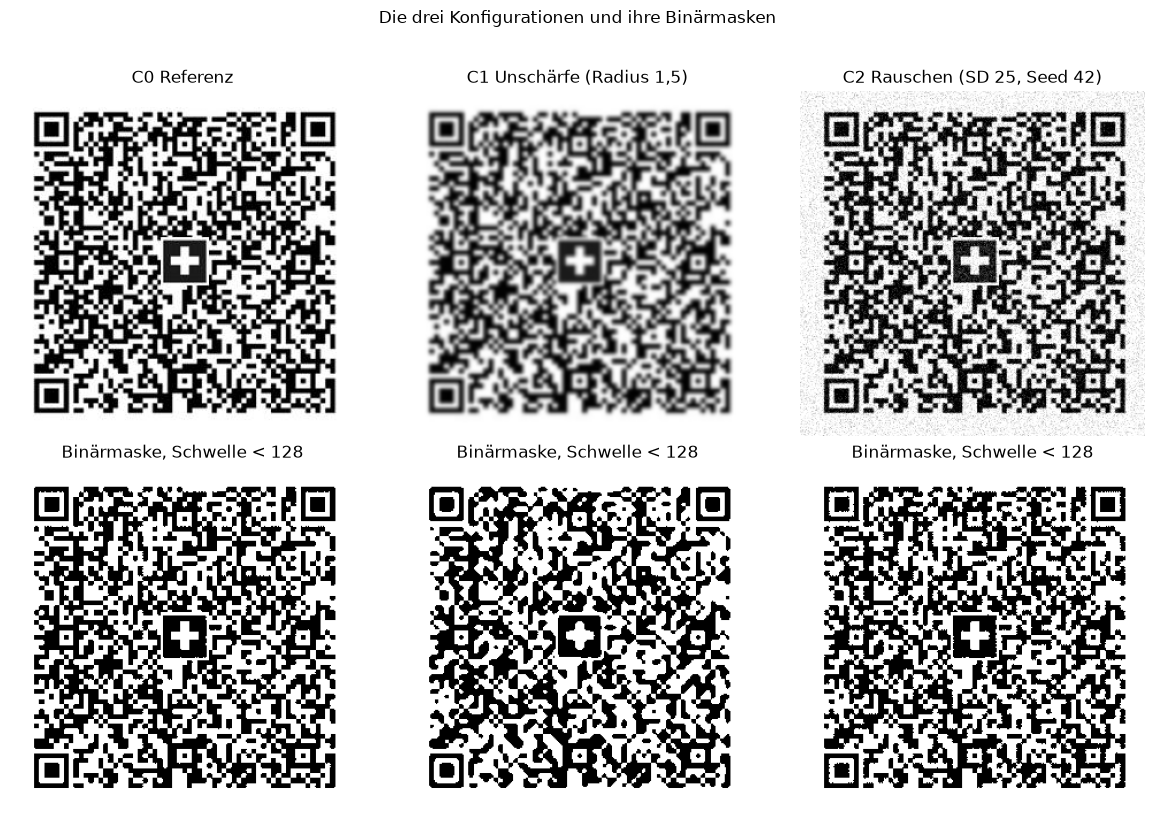

In [13]:
konfigurationen = {
    "C0 Referenz": qr_ausschnitt_grau.copy(),
    "C1 Unschärfe (Radius 1,5)": gauss_unschaerfe(qr_ausschnitt_grau, radius=1.5),
    "C2 Rauschen (SD 25, Seed 42)": gauss_rauschen(qr_ausschnitt_grau, standardabweichung=25, seed=42),
}

abbildung, achsen = plt.subplots(2, 3, figsize=(12, 8))
for spalte, (name, bild) in enumerate(konfigurationen.items()):
    achsen[0, spalte].imshow(bild, cmap="gray", vmin=0, vmax=255)
    achsen[0, spalte].set_title(name)
    achsen[0, spalte].axis("off")
    achsen[1, spalte].imshow(schwarzmaske(bild), cmap="gray_r", vmin=0, vmax=1)
    achsen[1, spalte].set_title("Binärmaske, Schwelle < 128")
    achsen[1, spalte].axis("off")
abbildung.suptitle("Die drei Konfigurationen und ihre Binärmasken", y=1.02)
abbildung.tight_layout()

**Kontrolle der Umsetzung:** Beide Funktionen behalten die ursprüngliche Bildgrösse bei und geben ein 8-Bit-Graustufenbild zurück. Beim Testbild sind die Unterschiede gut erkennbar: Die Unschärfe erzeugt durchgehend weichere Kanten, während das Rauschen viele kleine Helligkeitsschwankungen erzeugt. Die zweite Abbildung zeigt genau die Bilder und Masken, die am nächsten Tag ausgewertet werden.

## Day 4: Evaluation

*Focus: systematic, traceable evaluation of the predefined experiment design and its key parameters.*

<span style="background-color: #eeeeee;">*Systematically evaluate the predefined experiment design in relation to the defined use case. The evaluation must be traceable, structured, and based on consistent criteria. All reported metrics or extracted quantities must include appropriate physical units or clearly indicate normalization to ensure consistent and meaningful comparison. The same predefined evaluation approach must be applied consistently across all experiments and parameter configurations to maintain traceability and comparability. No new simulations, theoretical derivations, or interpretative discussion should be introduced.*</span>

### Evaluation Approach Definition

<span style="background-color: #eeeeee;">*Guidelines: Define 1–2 quantitative evaluation approaches, which may consist of numerical metrics and/or quantitatively interpretable visualizations. Justify why the selected approach is appropriate for your signal or image characteristics and application objective, and clearly specify what aspect of performance it captures (e.g., fidelity, detection accuracy, reconstruction quality, robustness, distortion). Visualizations must include labeled axes with units and enable measurable comparison across configurations. 2-3 sentences.*</span>

You may use the following structures as guidance, depending on whether your evaluation approach is metric-based or visualization-based.

#### Template – Metric-Based Evaluation

> The selected metric is __________, which quantifies ____________ in relation to [the defined use case].
It is specifically chosen because the problem statement requires accurate assessment of ____________, and this metric directly reflects changes in ____________.
The validity of this metric depends on ____________, which must hold for the evaluation to be meaningful in this application.

Example – Root Mean Squared Error (RMSE):

> The selected metric is RMSE, which quantifies the deviation between the reconstructed signal and the high-resolution reference. It is specifically chosen because [the use case] requires accurate amplitude reconstruction over time, and RMSE directly reflects reconstruction fidelity. The metric is meaningful here because a validated reference signal is available and serves as ground truth.

#### Template – Visualization-Based Evaluation

> The evaluation uses a __________ visualization, representing ____________ with clearly labeled axes and units.
The evaluated quantity is ____________, which is directly relevant to [the defined use case] because the problem requires reliable assessment of ____________.
This approach is appropriate under ____________, ensuring that the extracted feature meaningfully reflects performance in this application context.

Example – Frequency Spectrum Comparison:

> The evaluation uses a frequency spectrum visualization to assess whether dominant periodic components are preserved. The evaluated quantity is the measurable peak frequency and its amplitude, which are directly relevant because the use case requires reliable detection of periodic behavior. This approach is appropriate since frequency preservation is more critical than pointwise amplitude accuracy in this application.

### Evaluation Comparison Execution

<span style="background-color: #eeeeee;">*Guidelines: Apply the defined evaluation approach consistently across all predefined experiments or configurations. Systematically vary 2–4 previously defined key parameters and quantify their influence on performance relative to a clearly specified baseline configuration. Results must be reported in a structured format (e.g., tables or measurable graphics) to ensure traceability. 2-4 sentences.*</span>


#### Template – Parameter Evaluation (Metric-Based)

>The influence of key parameters __________ was evaluated using the previously defined metric __________.
These parameters are essential for [the defined use case] because they directly affect ____________, which is critical for ____________.
Changes in __________ [metric] across parameter settings quantify how sensitive the experiment design is to ____________.
Relative performance change was computed with respect to the baseline configuration ____________.

#### Template – Parameter Evaluation (Visualization-Based)

>The influence of key parameters __________ was evaluated using the previously defined visualization-based measure __________.
These parameters are essential for the defined use case because they influence ____________, which determines ____________ in [the application context].
Differences in the extracted quantity __________ across parameter settings quantify the impact of ____________ on performance.
Relative performance change was computed with respect to the baseline configuration ____________.

In [14]:
## Placeholder for code-based analysis, quantitative result reporting, and structured comparison using tables and/or graphics.

Example universal comparison table:

| Experiment / Configuration        | Metric / Quantity 1 | Metric / Quantity 2 (optional) | Relative Change to Baseline (%) |
|:----------------------------------|:--------------------|:--------------------------------|:--------------------------------|
| Baseline: ____________            |                     |                                  | 0%                               |
| Configuration 1: ____________     |                     |                                  |                                  |
| Configuration 2: ____________     |                     |                                  |                                  |
| Configuration 3: ____________     |                     |                                  |                                  |


Example for Sampling Rate Variation:


| Experiment / Configuration | RMSE | Relative Change to Baseline (%) |
|:----------------------------|:-----|:--------------------------------|
| Baseline: Fs = 100 Hz      | 0.12 | 0%                               |
| Fs = 50 Hz                 | 0.18 | +50%                             |
| Fs = 25 Hz                 | 0.45 | +275%                            |

## Day 5: Analysis & Communication

*Focus: Analytical Interpretation and Domain-Specific Discussion*

<span style="background-color: #eeeeee;">*Guidelines: Based on the quantitative evaluation from the Evaluation day, critically analyze your findings in direct relation to your defined use case and selected signal or image. Structure your analysis into (1) observations, (2) interpretation, and (3) discussion. Observations must reference concrete quantitative results; interpretations must explain domain-specific implications; the discussion must critically assess the practical applicability, limitations, and risks of your implementation and evaluation approach. All arguments must explicitly connect to the original problem statement and use case. No new simulations or derivations may be introduced.*</span>

### Observations (3-5 sentences)
Focus: Describe measurable results only — no explanation.

> The quantitative evaluation shows that ____________ changes from ____________ to ____________ across configurations ____________.
The defined metric / extracted quantity indicates that ____________.
Performance differences are most pronounced when ____________.

### Interpretation (3-5 sentences)
Focus: Explain what the results mean for the application.

>In the context of ____________ [use case], these results imply that ____________.
The observed variation in ____________ affects ____________ because ____________.
This suggests that ____________ is particularly critical for achieving the objective defined in the problem statement.


### Discussion and Critical Reflection (4–6 sentences)
*Focus: Relate the quantitative findings to the requirements of the defined use case and assess practical adequacy.*

> For the defined use case, the configurations ____________ performed well because they achieved ____________, which aligns with the requirement of ____________.
In contrast, configurations ____________ showed reduced performance, leading to ____________ and limiting their suitability for this application.
The achieved performance level can be considered sufficient / insufficient for the use case because ____________.
The implementation and evaluation approach assumes ____________, which may be constrained under real-world conditions such as ____________.
To improve robustness or applicability, future work should address ____________ or refine ____________.

## Day 15 

### Final Reflections on MC
>Overall, the most successful aspect of MC1 was ____________, particularly in relation to ____________ within the defined use case. The implementation of ____________ worked well because ____________, leading to ____________.
If repeating this work, I would reconsider ____________ or refine ____________, as this could improve ____________ and reduce ____________. Certain challenges emerged during ____________, highlighting the importance of ____________ in practical signal/image analysis.
I was particularly impressed by ____________, especially how ____________ influenced ____________ in the context of the application.
Through this project, I learned that ____________, and I developed a clearer understanding of ____________, especially regarding the connection between theoretical principles and real-world constraints.

### Revisions
<span style="background-color: #fff3b0;"><strong>Template for Revisions:</strong> [your changes... ]</span>